In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load dataset inbuild iris dataset in scikit-learn
iris = load_iris()
X, y = iris.data, iris.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train KNN classifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Evaluate
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


## Part 2: KNN on a Real-World Weather Dataset

## Step 1: Data Acquisition

### Objective
The objective of this step is to collect weather data that
we can use for exploratory data analysis and KNN classification.

### Steps
1. Load weather data from the API.
2. Clean and preprocess the data.
3. Select features and create target labels.
4. Train the KNN model using an ML Pipeline.
5. Evaluate accuracy and visualize results.

### Data Source
We are using the Open-Meteo Weather API to collect hourly
weather data for Berlin, Germany.

The dataset contains the following information:
- **Time:** Date and time of the weather record.
- **Temperature:** Air temperature in degrees Celsius.
- **Relative Humidity:** Amount of moisture in the air (%).
- **Precipitation:** Amount of rainfall or other precipitation (mm).
- **Wind Speed:** Wind speed measured in km/h.

### Why are we using this dataset?
This dataset contains numerical weather features that we
can analyze and use in a KNN classification model.

Our goal is to classify weather conditions as rainy or
not rainy based on weather measurements.

In [10]:
import requests
import pandas as pd

# Open-Meteo API URL
url = "https://api.open-meteo.com/v1/forecast"

# Weather data for Berlin, Germany
params = {
    "latitude": 52.52,
    "longitude": 13.41,
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "wind_speed_10m"
    ],
    "forecast_days": 7,
    "timezone": "Europe/Berlin"
}

# Request weather data
response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

# Convert API response to JSON
data = response.json()

# Convert JSON data into a Pandas DataFrame
weather_df = pd.DataFrame(data["hourly"])

# Convert time column to datetime format
weather_df["time"] = pd.to_datetime(weather_df["time"])

# Display dataset information
print("Dataset Shape:", weather_df.shape)

print("\nColumn Names:")
print(weather_df.columns.tolist())

print("\nFirst 5 Records:")
display(weather_df.head())

# Save the weather dataset for reproducibility
weather_df.to_csv(
    "weather_data.csv",
    index=False
)

print("\nWeather dataset saved successfully.")

Dataset Shape: (168, 5)

Column Names:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m']

First 5 Records:


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2026-10-11 00:00:00,11.9,68,0.0,10.5
1,2026-10-11 01:00:00,11.4,71,0.0,11.2
2,2026-10-11 02:00:00,10.8,73,0.0,12.0
3,2026-10-11 03:00:00,10.6,74,0.0,12.2
4,2026-10-11 04:00:00,10.1,77,0.0,11.5



Weather dataset saved successfully.


### Data Acquisition — Observations 

**What did we do?**

We successfully retrieved hourly weather data from the
Open-Meteo API and converted the JSON response into a
Pandas DataFrame.

**Why did we use Pandas?**

Pandas helps us organize data into rows and columns.
It makes it easier to inspect, clean, analyze and prepare
the data for machine learning.

**What does the dataset shape mean?**

The dataset contains 168 rows and 5 columns.

- Each row represents one hourly weather record.
- Each column represents a weather attribute.
- The dataset contains seven days of hourly forecast data.

**How does this help our KNN project?**

We need a structured dataset before training a machine
learning model. This data will allow us to analyze
weather patterns and later classify rainy and
non-rainy conditions.

#### Dataset Reproducibility

We saved the collected weather data as a CSV file named
`weather_data.csv`.

This allows all team members to use the same dataset
without repeatedly requesting updated forecast data.

It also helps make our machine learning results
more reproducible.



## Step 2: Data Inspection and Descriptive Statistics

### Objective
Before using the dataset for machine learning, we need to
understand its structure and check its quality.

We will perform the following tasks:

1. Check the number of rows and columns.
2. Examine the data types of each column.
3. Identify missing values.
4. Check for duplicate records.
5. Generate descriptive statistics.

### Why is this important?

- Missing values can affect machine learning performance.
- Incorrect data types can cause errors during analysis.
- Duplicate records may affect our results.
- Descriptive statistics help us understand the range
  and average values of weather measurements.


In [11]:
# Step 2: Data Inspection and Descriptive Statistics

# 1. Display dataset structure
print("Dataset Information:")
weather_df.info()

# 2. Check column data types
print("\nData Types:")
display(weather_df.dtypes.to_frame(name="Data Type"))

# 3. Check missing values
print("\nMissing Values:")

missing_values = pd.DataFrame({
    "Missing Count": weather_df.isnull().sum(),
    "Missing Percentage": (
        weather_df.isnull().mean() * 100
    ).round(2)
})

display(missing_values)

# 4. Check duplicate records
print("\nDuplicate Records:")
print(weather_df.duplicated().sum())

# Descriptive statistics for numerical features
print("\nDescriptive Statistics:")

numerical_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m"
]

statistics = weather_df[numerical_features].describe()

# Round values for better readability
display(statistics.round(2))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  168 non-null    datetime64[us]
 1   temperature_2m        168 non-null    float64       
 2   relative_humidity_2m  168 non-null    int64         
 3   precipitation         168 non-null    float64       
 4   wind_speed_10m        168 non-null    float64       
dtypes: datetime64[us](1), float64(3), int64(1)
memory usage: 6.7 KB

Data Types:


,Data Type
time,datetime64[us]
temperature_2m,float64
relative_humidity_2m,int64
precipitation,float64
wind_speed_10m,float64



Missing Values:


,Missing Count,Missing Percentage
time,0,0.0
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
precipitation,0,0.0
wind_speed_10m,0,0.0



Duplicate Records:
0

Descriptive Statistics:


,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
count,168.00,168.00,168.00,168.00
mean,11.52,76.12,0.02,7.62
std,3.35,14.24,0.12,3.66
min,3.10,44.00,0.00,1.10
25%,9.30,64.75,0.00,4.10
50%,11.60,78.50,0.00,7.80
75%,13.80,89.00,0.00,10.50
max,19.30,99.00,1.40,16.00


### Data Quality Findings

After inspecting the dataset, we found:

- The dataset contains 168 rows and 5 columns.
- All columns have appropriate data types.
- There are no missing values in any column.
- There are no duplicate records.

### Decision

Since there are no missing values or duplicate records, we do not need to perform missing-value imputation or duplicate removal at this stage.


### Understanding Descriptive Statistics

Descriptive statistics help us understand the numerical
characteristics of the dataset.

- **Count:** Number of available records.
- **Mean:** Average value of a weather feature.
- **Standard Deviation:** How much the values vary.
- **Minimum:** Smallest recorded value.
- **25%:** First quartile (Q1).
- **50%:** Median value.
- **75%:** Third quartile (Q3).
- **Maximum:** Largest recorded value.

These statistics help us identify patterns and unusual values
before building the KNN model.


## Step 3: Data Distribution Visualization

### Objective

The goal of this step is to understand how different weather
features are distributed across the dataset.

We will create histograms for:

1. Temperature
2. Relative Humidity
3. Precipitation
4. Wind Speed

### What is a Histogram?

A histogram shows how frequently different numerical values
occur in a dataset.

For example, a temperature histogram helps us identify
which temperature ranges occur most frequently.

### Why is this important for KNN?

KNN calculates distances between data points.

Understanding feature distributions helps us identify
unusual values, differences in feature scales, and
potential data imbalance.


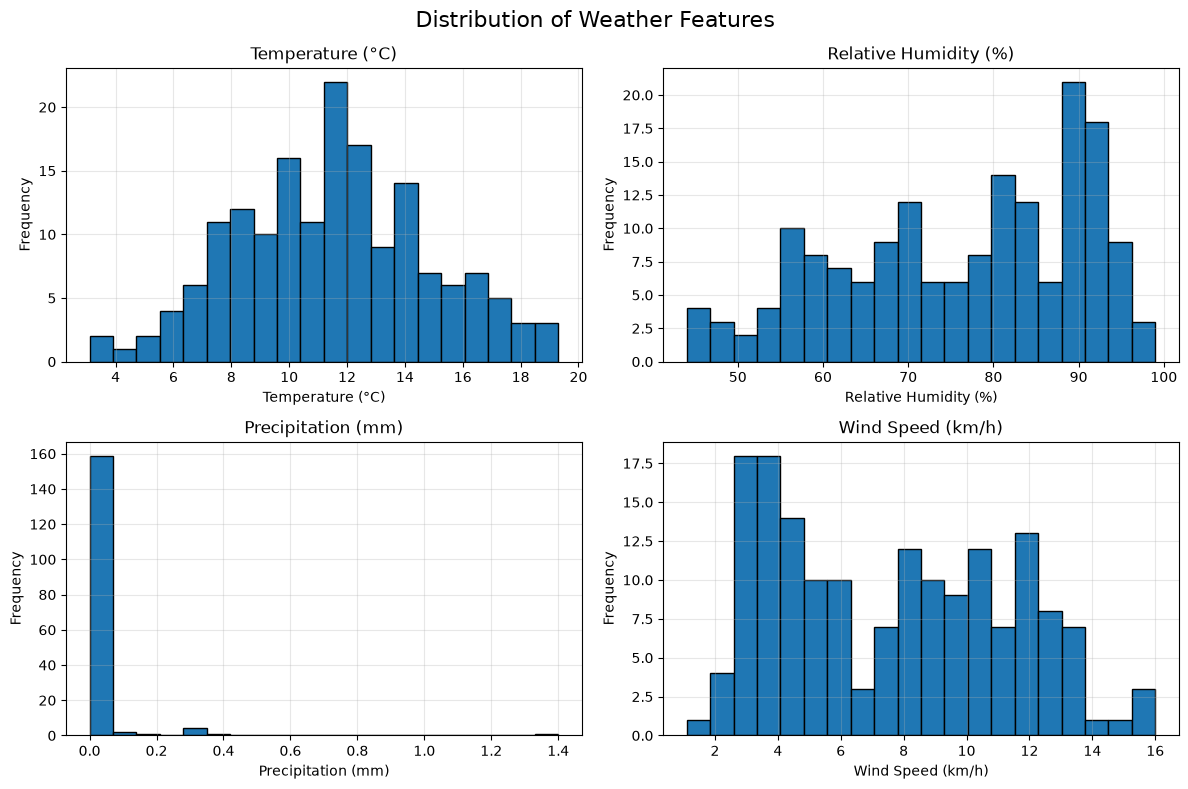

In [12]:
import matplotlib.pyplot as plt

# Weather features and their labels
features = {
    "temperature_2m": "Temperature (°C)",
    "relative_humidity_2m": "Relative Humidity (%)",
    "precipitation": "Precipitation (mm)",
    "wind_speed_10m": "Wind Speed (km/h)"
}

# Create histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, label) in zip(
    axes.flatten(),
    features.items()
):
    ax.hist(
        weather_df[column].dropna(),
        bins=20,
        edgecolor="black"
    )

    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Distribution of Weather Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

#### Histogram Analysis — Observations

After visualizing the weather dataset, we observed the following:

- **Temperature:** Most temperature values are between 7°C and 14°C, with the highest frequency around 10–11°C.
- **Humidity:** Many humidity values are concentrated between 85% and 94%, indicating frequent high-humidity conditions.
- **Precipitation:** Most records have zero precipitation, while only a small number of hours show rainfall or other precipitation.
- **Wind Speed:** Wind speed values are spread across approximately 2–18 km/h.

### Key Findings

The precipitation histogram shows that the dataset contains mostly zero-precipitation records. This suggests a possible class imbalance between rainy and non-rainy conditions.

Since we are using KNN for classification, class imbalance may affect model performance.


## Step 4: Boxplots and Outlier Analysis

### Objective

The purpose of this step is to identify unusual values
in our weather dataset using boxplots.

### What is a Boxplot?

A boxplot shows the distribution of numerical data using:

- **Median:** The middle value of the dataset.
- **Q1:** The 25th percentile.
- **Q3:** The 75th percentile.
- **Whiskers:** The range of values within the boxplot limits.
- **Outliers:** Values outside the whiskers that may be unusual.

### Why is this important for KNN?

KNN uses distance calculations to identify nearby data points.

Unusual values and different feature scales can affect
these calculations.

However, unusual weather values are not always errors.
They may represent real weather conditions.


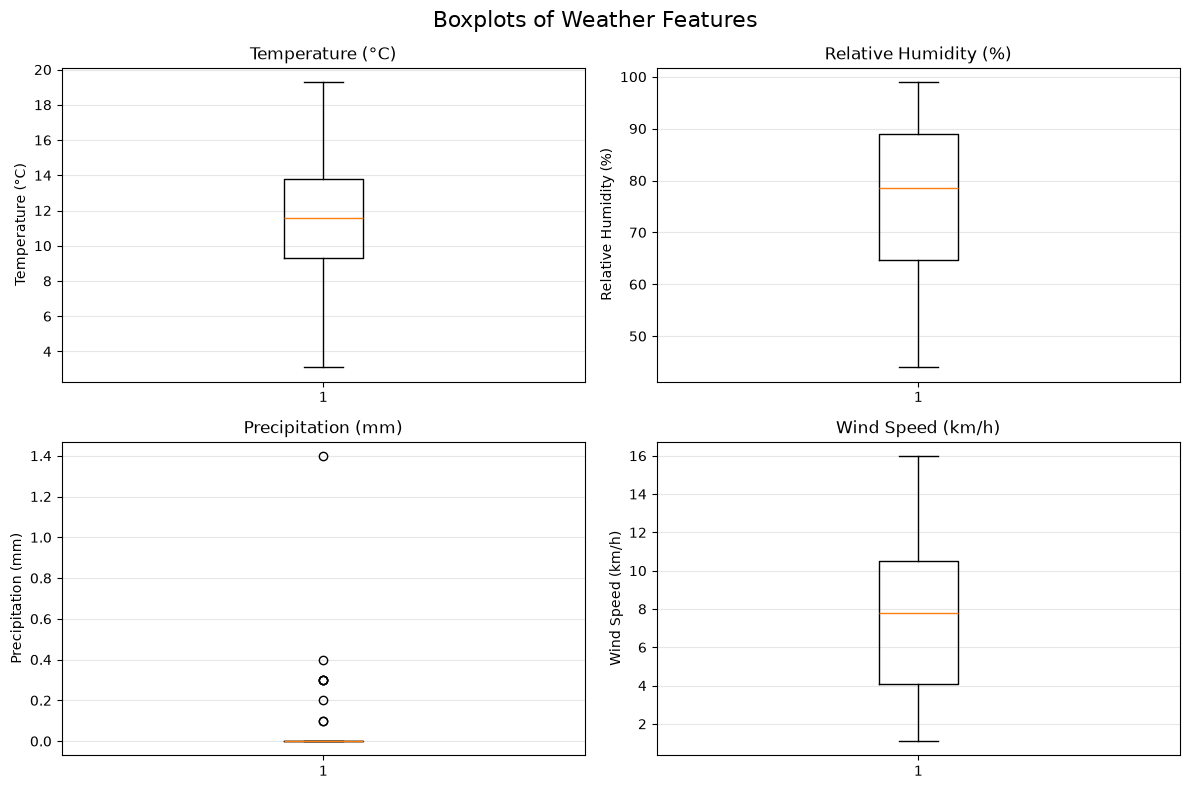

In [13]:
import matplotlib.pyplot as plt

features = {
    "temperature_2m": "Temperature (°C)",
    "relative_humidity_2m": "Relative Humidity (%)",
    "precipitation": "Precipitation (mm)",
    "wind_speed_10m": "Wind Speed (km/h)"
}

# Create boxplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, label) in zip(
    axes.flatten(),
    features.items()
):
    ax.boxplot(
        weather_df[column].dropna()
    )

    ax.set_title(label)
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Boxplots of Weather Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

#### Boxplot Analysis — Observations

We created boxplots to identify potential outliers in the weather dataset.

- **Temperature:** The values are distributed within the expected range, with no visible outliers.
- **Humidity:** No significant outliers were detected.
- **Precipitation:** Several positive precipitation values appear as outliers because most records contain zero precipitation.
- **Wind Speed:** The values show some variation, but no visible outliers were detected.

### Decision on Outlier Handling

We decided not to remove the precipitation outliers because they represent actual forecast weather conditions.

Removing these values could negatively affect our KNN classification model, as we are trying to distinguish between rainy and non-rainy conditions.

## Step 5: Target Class Distribution

### Objective

The purpose of this step is to understand how many weather
records represent rainy and non-rainy conditions.

### Target Variable

We create a new column called `rainy` using precipitation:

- 0 = Not Rainy (precipitation is zero)
- 1 = Rainy (precipitation is greater than zero)

### Why is this important?

KNN is a classification algorithm that learns from
labeled data.

By examining the number of rainy and non-rainy records,
we can determine whether our target classes are balanced.

An imbalanced dataset may cause the model to predict
the majority class more frequently.


,Class,Count,Percentage (%)
0,Not Rainy,159,94.64
1,Rainy,9,5.36


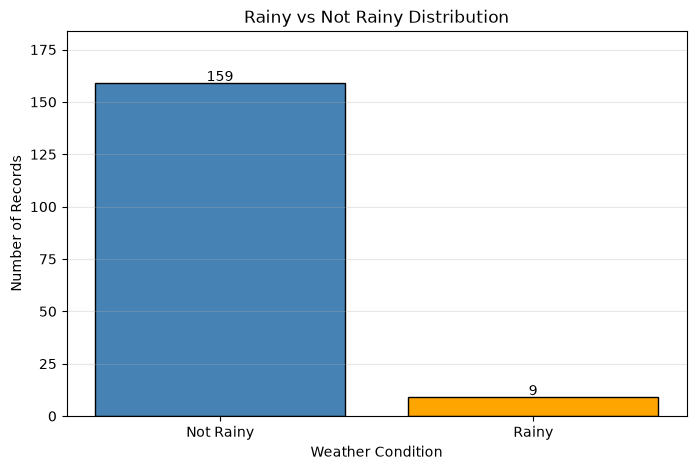

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a copy of the original weather dataset
clean_df = weather_df.copy()

# Create binary target variable
clean_df["rainy"] = (
    clean_df["precipitation"] > 0
).astype(int)

# Count records in each class
class_counts = clean_df["rainy"].value_counts().reindex(
    [0, 1],
    fill_value=0
)

# Calculate percentages
class_percentages = (
    class_counts / len(clean_df) * 100
).round(2)

# Display class distribution
class_distribution = pd.DataFrame({
    "Class": ["Not Rainy", "Rainy"],
    "Count": class_counts.values,
    "Percentage (%)": class_percentages.values
})

display(class_distribution)

# Visualize class distribution
plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_distribution["Class"],
    class_distribution["Count"],
    color=["steelblue", "orange"],
    edgecolor="black"
)

# Display counts above the bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{int(height)}",
        ha="center"
    )

plt.title("Rainy vs Not Rainy Distribution")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Records")
plt.ylim(0, max(class_counts) * 1.15 + 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Step 5: Class Distribution — Observations

We created a new target variable called `rainy` based on precipitation values.

- **Not Rainy (0):** 149 records (88.69%)
- **Rainy (1):** 19 records (11.31%)
- **Total:** 168 records

### Key Finding

The dataset is imbalanced because most records belong to the non-rainy class.

This could affect our KNN model because it may predict non-rainy conditions more frequently than rainy conditions.

Therefore, model evaluation should include precision, recall, F1-score, and a confusion matrix.


## Data Cleaning and Feature Engineering

This section validates the weather data, removes duplicate records, creates numerical time-based features, selects input features and the target, and splits the dataset into training and testing sets. Missing-value imputation and feature scaling are handled by the KNN pipeline.

In [15]:
# Data Cleaning and Feature Engineering

import numpy as np
from sklearn.model_selection import train_test_split

# 1. Convert time to datetime
clean_df["time"] = pd.to_datetime(
    clean_df["time"], errors="coerce"
)

# 2. Remove invalid timestamps and duplicates
clean_df = clean_df.dropna(subset=["time"])
clean_df = clean_df.drop_duplicates()

# 3. Create numerical time-based features
clean_df["hour"] = clean_df["time"].dt.hour

clean_df["hour_sin"] = np.sin(
    2 * np.pi * clean_df["hour"] / 24
)
clean_df["hour_cos"] = np.cos(
    2 * np.pi * clean_df["hour"] / 24
)

# 4. Select features (X)
# Exclude precipitation because it defines the target
X = clean_df[
    [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "hour_sin",
        "hour_cos"
    ]
]

# 5. Select target (y)
y = clean_df["rainy"]

# 6. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 7. Display validation results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (134, 5)
Testing features: (34, 5)
Training target: (134,)
Testing target: (34,)


### Summary of Data Cleaning and Feature Engineering

The weather dataset was prepared for KNN classification by converting the timestamp to datetime format, removing invalid timestamps and duplicate records, and creating numerical time-based features using sine and cosine transformations.

The input features (`X`) were selected using temperature, relative humidity, wind speed, and the engineered time features. The target variable (`y`) was `rainy`, representing whether precipitation occurred. Precipitation was excluded from the input features to avoid target leakage.

The dataset was split into training and testing sets using an 80:20 ratio. Missing-value imputation and feature scaling are handled by the existing KNN pipeline to prepare the data for model training.
**Categorical Encoding Decision**

The selected input features are numerical, so one-hot encoding or label encoding is not required. The timestamp was converted to datetime format, and the hour was transformed into sine and cosine features to represent its cyclical nature.

## EDA Summary and Conclusion

### Summary

In this workshop, we collected and explored weather data using the Open-Meteo API.

The dataset contains 168 hourly weather records with information about temperature, humidity, precipitation and wind speed.

We performed data inspection, missing-value analysis, descriptive statistics and data visualizations.

### Key Findings

- The dataset contains no missing values or duplicate records.
- The average temperature is approximately 11.27°C.
- The average humidity is approximately 75.07%.
- Most records have zero precipitation.
- We identified some positive precipitation values as statistical outliers but retained them because they represent important weather conditions.
- The target classes are imbalanced, with 149 non-rainy records (88.69%) and 19 rainy records (11.31%).

### Dataset Limitations

The dataset covers only seven days of hourly weather forecasts from Berlin, Germany. Therefore, it may not represent longer-term or seasonal weather patterns.

The dataset also contains relatively few rainy records, which may make it difficult for the model to identify rainy conditions accurately.

### Conclusion

Our exploratory data analysis helped us understand the structure, quality and distribution of weather data.

The dataset is ready for the next preprocessing stage, including feature selection, scaling and train-test splitting.

The class imbalance should be considered when training and evaluating the KNN model.


### Step 6: KNN Model Training Using ML Pipeline

We create a machine learning pipeline with three steps:

1. **SimpleImputer:** Handles missing values using the median.
2. **StandardScaler:** Scales features so they contribute fairly to distance calculations.
3. **KNeighborsClassifier:** Classifies weather conditions using the 3 nearest neighbors.

The pipeline combines preprocessing and model training into one workflow.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Create KNN pipeline
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3))
])

# Train the model
knn_pipeline.fit(X_train, y_train)

# Make predictions
y_pred = knn_pipeline.predict(X_test)

print("KNN model trained successfully!")
print("Predictions:", y_pred)

KNN model trained successfully!
Predictions: [0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
